<h1>Оглавление<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Загрузка-данных" data-toc-modified-id="Загрузка-данных-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Загрузка данных</a></span></li><li><span><a href="#Предобработка-данных" data-toc-modified-id="Предобработка-данных-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Предобработка данных</a></span></li><li><span><a href="#Исследовательский-анализ-данных" data-toc-modified-id="Исследовательский-анализ-данных-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Исследовательский анализ данных</a></span></li><li><span><a href="#Объединение-таблиц" data-toc-modified-id="Объединение-таблиц-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Объединение таблиц</a></span></li><li><span><a href="#Корреляционный-анализ" data-toc-modified-id="Корреляционный-анализ-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Корреляционный анализ</a></span></li><li><span><a href="#Использование-пайплайнов" data-toc-modified-id="Использование-пайплайнов-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Использование пайплайнов</a></span></li><li><span><a href="#Анализ-важности-признаков" data-toc-modified-id="Анализ-важности-признаков-7"><span class="toc-item-num">7&nbsp;&nbsp;</span>Анализ важности признаков</a></span></li><li><span><a href="#Сегментация-покупателей" data-toc-modified-id="Сегментация-покупателей-8"><span class="toc-item-num">8&nbsp;&nbsp;</span>Сегментация покупателей</a></span></li><li><span><a href="#Общий-вывод" data-toc-modified-id="Общий-вывод-9"><span class="toc-item-num">9&nbsp;&nbsp;</span>Общий вывод</a></span></li></ul></div>

# Проект "Обучение с учителем: качество модели"

__Описание проекта__:
<div style="background-color: white; color: maroon;">
    Интернет-магазин «В один клик» продаёт разные товары: для детей, для дома, мелкую бытовую технику, косметику и даже продукты. Отчёт магазина за прошлый период показал, что активность покупателей начала снижаться. Привлекать новых клиентов уже не так эффективно: о магазине и так знает большая часть целевой аудитории. Возможный выход — удерживать активность постоянных клиентов. Сделать это можно с помощью персонализированных предложений.
<br/>
<br/>
    «В один клик» — современная компания, поэтому её руководство не хочет принимать решения просто так — только на основе анализа данных и бизнес-моделирования. У компании есть небольшой отдел цифровых технологий, и вам предстоит побыть в роли стажёра в этом отделе.
<br/>
<br/>
    Итак, вашему отделу поручили разработать решение, которое позволит персонализировать предложения постоянным клиентам, чтобы увеличить их покупательскую активность.
</div>

__План__:
1. Загрузка данных;
2. Предобработка даннных;
3. Исследовательский анализ данных;
4. Объединение датасетов;
5. Корреляционный анализ;
6. Создание пайплайнов;
7. Анализ важности признаков;
8. Сегментация покупателей;
9. Выводы.

<div style="background-color: white; color: olive;">
    Для начала импортируем всё (будет дополняться)!
</div>

In [76]:
!pip install phik -q
!pip install shap -q

from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)

import shap
from phik import resources, report
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import contingency, chi2_contingency
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import (OneHotEncoder,
                                   StandardScaler,
                                   LabelEncoder,
                                   OrdinalEncoder)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score,
                             recall_score,
                             precision_score,
                             confusion_matrix,
                             classification_report,
                             r2_score, mean_squared_error,
                             mean_absolute_error,
                             precision_recall_curve,
                             make_scorer,
                             f1_score,
                             roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

## Загрузка данных

<div style="background-color: white; color: olive;">
    Теперь датасеты!
</div>

In [77]:
market_file = pd.read_csv('market_file.csv', sep=',')
market_money = pd.read_csv('market_money.csv', sep=',')
market_time = pd.read_csv('market_time.csv', sep=',')
money = pd.read_csv('money.csv', sep=';', decimal = ',')

## Предобработка данных

<div style="background-color: white; color: olive;">
    Взглянем на то, как эти чудики выглядят.
</div>

In [78]:
print('market_file:')
display(market_file.head())
market_file.info()
print()
print('market_money:')
display(market_money.head())
market_money.info()
print()
print('market_time:')
display(market_time.head())
market_time.info()
print()
print('money:')
display(money.head())
money.info()

market_file:


,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит
0,215348,Снизилась,премиум,да,3.4,5,121,0.00,Товары для детей,6,2,1,5
1,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5
2,215350,Снизилась,стандартт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5
3,215351,Снизилась,стандартт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4
4,215352,Снизилась,стандартт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   id                                   1300 non-null   int64  
 1   Покупательская активность            1300 non-null   object 
 2   Тип сервиса                          1300 non-null   object 
 3   Разрешить сообщать                   1300 non-null   object 
 4   Маркет_актив_6_мес                   1300 non-null   float64
 5   Маркет_актив_тек_мес                 1300 non-null   int64  
 6   Длительность                         1300 non-null   int64  
 7   Акционные_покупки                    1300 non-null   float64
 8   Популярная_категория                 1300 non-null   object 
 9   Средний_просмотр_категорий_за_визит  1300 non-null   int64  
 10  Неоплаченные_продукты_штук_квартал   1300 non-null   int64  
 11  Ошибка_сервиса                

,id,Период,Выручка
0,215348,препредыдущий_месяц,0.0
1,215348,текущий_месяц,3293.1
2,215348,предыдущий_месяц,0.0
3,215349,препредыдущий_месяц,4472.0
4,215349,текущий_месяц,4971.6


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       3900 non-null   int64  
 1   Период   3900 non-null   object 
 2   Выручка  3900 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 91.5+ KB

market_time:


,id,Период,минут
0,215348,текущий_месяц,14
1,215348,предыдцщий_месяц,13
2,215349,текущий_месяц,10
3,215349,предыдцщий_месяц,12
4,215350,текущий_месяц,13


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2600 non-null   int64 
 1   Период  2600 non-null   object
 2   минут   2600 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 61.1+ KB

money:


,id,Прибыль
0,215348,0.98
1,215349,4.16
2,215350,3.13
3,215351,4.87
4,215352,4.21


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       1300 non-null   int64  
 1   Прибыль  1300 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 20.4 KB


<div style="background-color: white; color: olive;">
    Так, что мы видим? У нас четыре набора данных, в каждом наборе поровну ненулевых значений каждого класса (что радует!), но некоторые вещи немного пугают: "стандартт", "предыдцщий_месяц", "препредыдущий_месяц". Так что взглянем на очепятки и неявные дубликаты!
</div>

In [79]:
display(market_file['Покупательская активность'].unique())

array(['Снизилась', 'Прежний уровень'], dtype=object)

In [80]:
display(market_file['Тип сервиса'].unique())

array(['премиум', 'стандартт', 'стандарт'], dtype=object)

<div style="background-color: white; color: olive;">
    Вряд ли тип сервиса "стандартт" назван в честь пистолета ТТ. Заменим!
</div>

In [81]:
market_file['Тип сервиса'] = market_file['Тип сервиса'].replace('стандартт', 'стандарт')

In [82]:
display(market_file['Разрешить сообщать'].unique())

array(['да', 'нет'], dtype=object)

In [83]:
display(market_file['Популярная_категория'].unique())

array(['Товары для детей', 'Домашний текстиль', 'Косметика и аксесуары',
       'Техника для красоты и здоровья', 'Кухонная посуда',
       'Мелкая бытовая техника и электроника'], dtype=object)

In [84]:
display(market_money['Период'].unique())

array(['препредыдущий_месяц', 'текущий_месяц', 'предыдущий_месяц'],
      dtype=object)

<div style="background-color: white; color: olive;">
    У нас идёт отслеживание за три месяца. Скорее всего, "препредыдущий_месяц" это предпредыдущий месяц.
</div>

In [85]:
market_money['Период'].value_counts()

текущий_месяц          1300
препредыдущий_месяц    1300
предыдущий_месяц       1300
Name: Период, dtype: int64

In [86]:
market_money['Период'] = market_money['Период'].replace('препредыдущий_месяц', 'предпредыдущий_месяц')

In [87]:
display(market_time['Период'].unique())

array(['текущий_месяц', 'предыдцщий_месяц'], dtype=object)

<div style="background-color: white; color: olive;">
    А тут за два месяца, чего? Может, в том случае "предпредыдущий" это была опечатка в "предыдущий"? Но в условии чётко написано: "Период — название периода, во время которого зафиксирована выручка. Например, 'текущий_месяц' или 'предыдущий_месяц'." Из-за слова "например", можно сказать, что, помимо двух признаков, возможн ещё -- к примеру, "предпредыдущий". Чёрт ногу сломит! Добавил счётчик. Судя по количеству значений, там реально три месяца, а тут -- два. АААААААААА!
</div>

In [88]:
market_time['Период'] = market_time['Период'].replace('предыдцщий_месяц', 'предыдущий_месяц')

In [89]:
display(market_file.isnull().sum())
display(market_money.isnull().sum())
display(market_time.isnull().sum())
display(money.isnull().sum())

id                                     0
Покупательская активность              0
Тип сервиса                            0
Разрешить сообщать                     0
Маркет_актив_6_мес                     0
Маркет_актив_тек_мес                   0
Длительность                           0
Акционные_покупки                      0
Популярная_категория                   0
Средний_просмотр_категорий_за_визит    0
Неоплаченные_продукты_штук_квартал     0
Ошибка_сервиса                         0
Страниц_за_визит                       0
dtype: int64

id         0
Период     0
Выручка    0
dtype: int64

id        0
Период    0
минут     0
dtype: int64

id         0
Прибыль    0
dtype: int64

<div style="background-color: white; color: olive;">
    Бинго!
</div>

In [90]:
display(market_file.duplicated().sum())
display(market_money.duplicated().sum())
display(market_time.duplicated().sum())
display(money.duplicated().sum())

0

0

0

0

## Исследовательский анализ данных

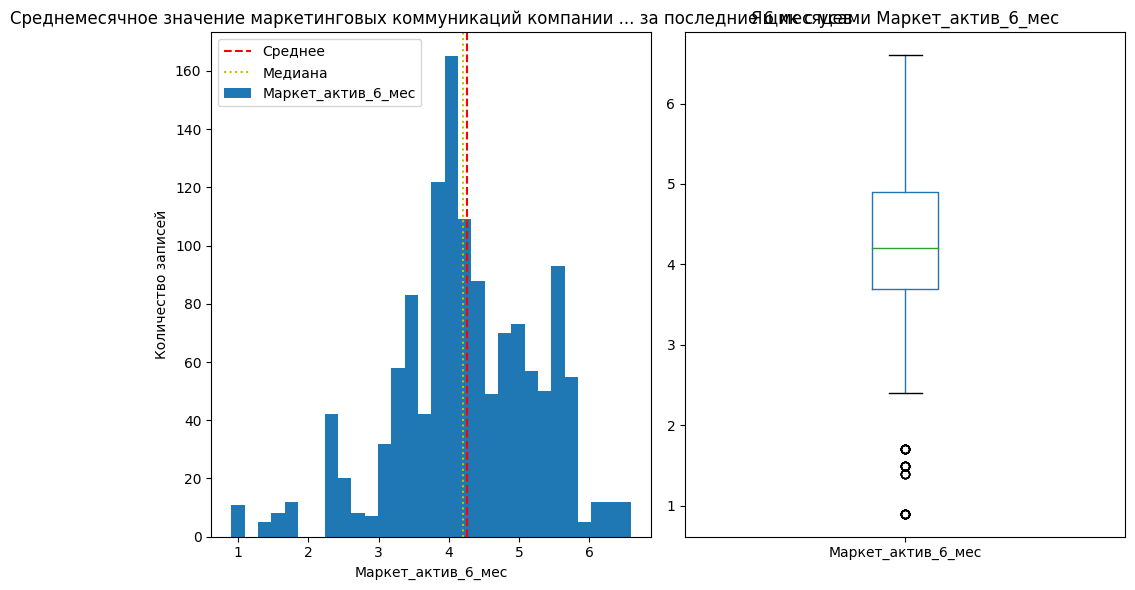

In [91]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Маркет_актив_6_мес'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Среднемесячное значение маркетинговых коммуникаций компании ... за последние 6 месяцев')
ax1.set_xlabel('Маркет_актив_6_мес')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Маркет_актив_6_мес'].mean()
median_value = market_file['Маркет_актив_6_мес'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Маркет_актив_6_мес'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Ящик с усами Маркет_актив_6_мес')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Большинство значений сосредоточено в диапазоне от 2 до 5.
<br/>
<br/>
    Среднее значение (красная пунктирная линия) находится около 4.
<br/>
<br/>
    Медиана (желтая пунктирная линия) также находится около 4, что говорит о симметричном распределении вокруг центра
<br/>
<br/>
    Имеется несколько выбросов снизу под ящиком с усами.
</div>

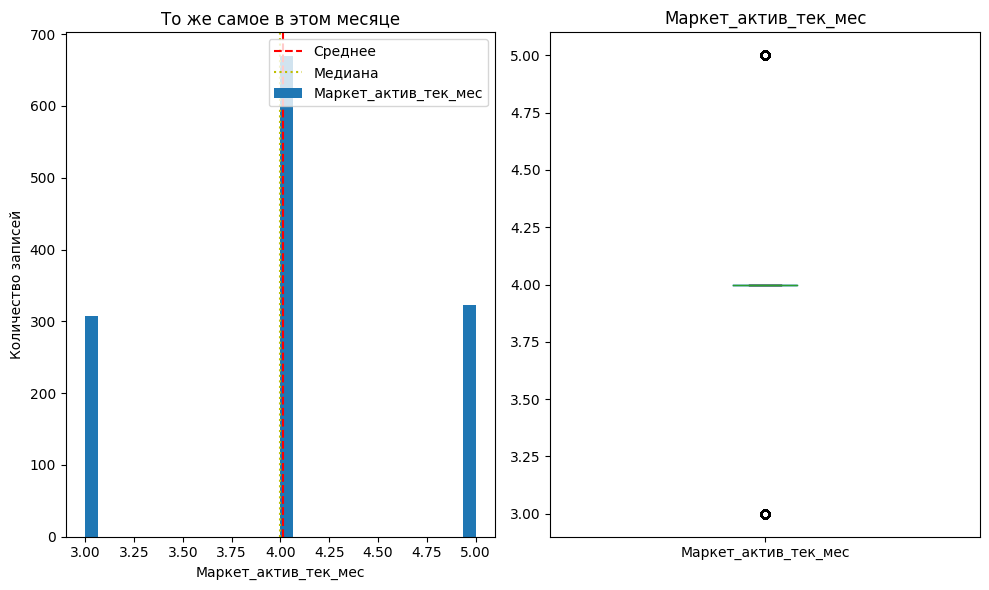

In [92]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Маркет_актив_тек_мес'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('То же самое в этом месяце')
ax1.set_xlabel('Маркет_актив_тек_мес')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Маркет_актив_тек_мес'].mean()
median_value = market_file['Маркет_актив_тек_мес'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Маркет_актив_тек_мес'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Маркет_актив_тек_мес')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Тут у нас мультимодальное распределение с тремя пиками: 3, 4, 5.
<br/>
<br/>
    Из-за чёткой концентрации данных вокруг трёх пиков, у нас очень короткие усы и выбросы на крайних пиках.
</div>

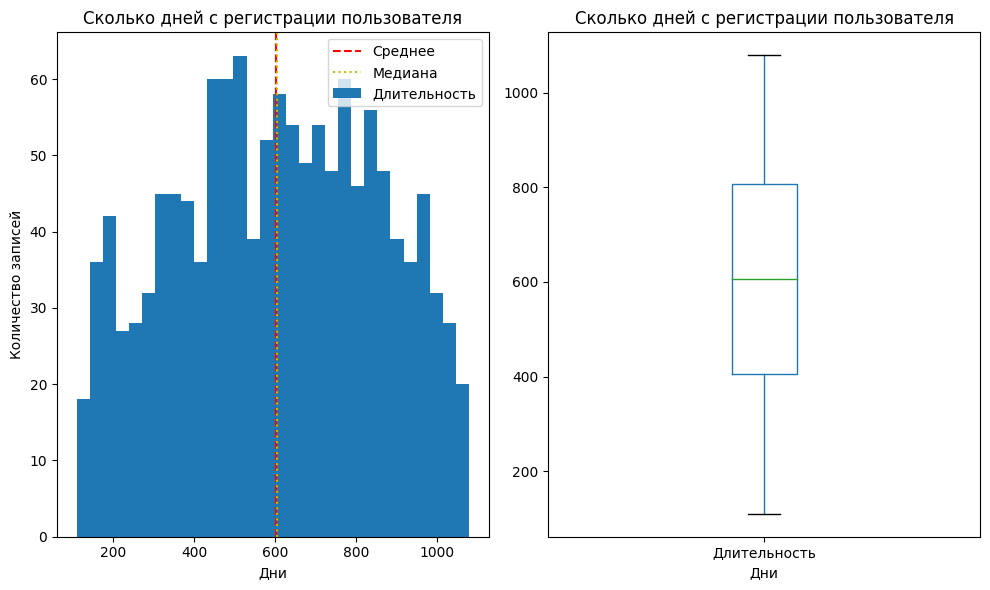

In [93]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Длительность'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Сколько дней с регистрации пользователя')
ax1.set_xlabel('Дни')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Длительность'].mean()
median_value = market_file['Длительность'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Длительность'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Сколько дней с регистрации пользователя')
ax2.set_xlabel('Дни')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределение является правосторонне асимметричным (положительная асимметрия).
<br/>
<br/>
Большинство пользователей зарегистрировалось от 200 до 600 дней назад.
<br/>
<br/>
Среднее значение (красная пунктирная линия) находится около 600 дней.
<br/>
<br/>
Медиана (желтая пунктирная линия) также находится около 600 дней, что говорит о том, что половина пользователей зарегистрировалась более 600 дней назад.
</div>

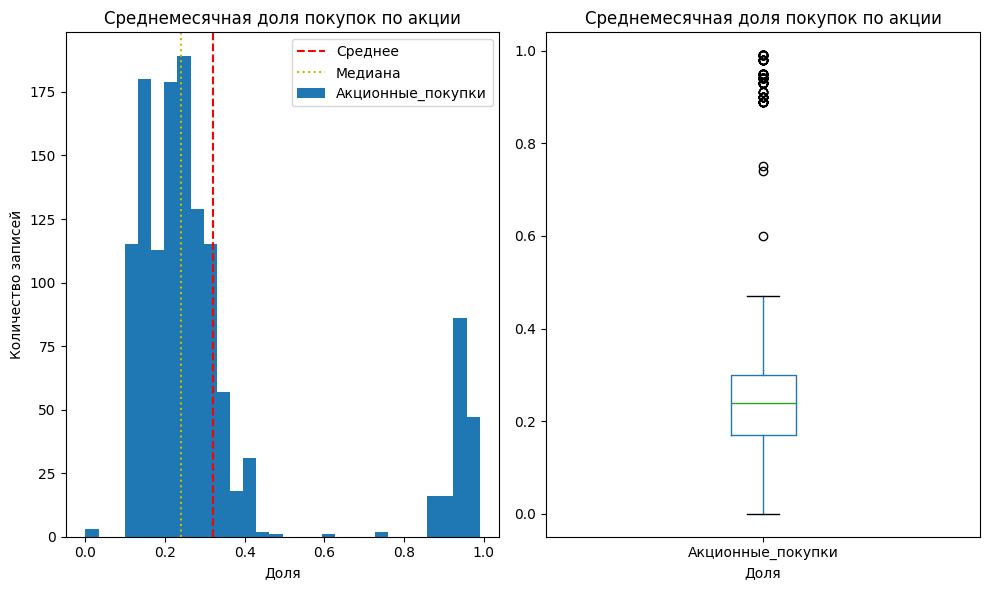

In [94]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Акционные_покупки'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Среднемесячная доля покупок по акции')
ax1.set_xlabel('Доля')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Акционные_покупки'].mean()
median_value = market_file['Акционные_покупки'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Акционные_покупки'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Среднемесячная доля покупок по акции')
ax2.set_xlabel('Доля')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    И тут снова нечто похожее на бимодальное распределение, где левый пик сильно крупнее правого, т.е. распределение можно охарактеризовать как положительно асимметричное с элементами бимодальности.
</div>

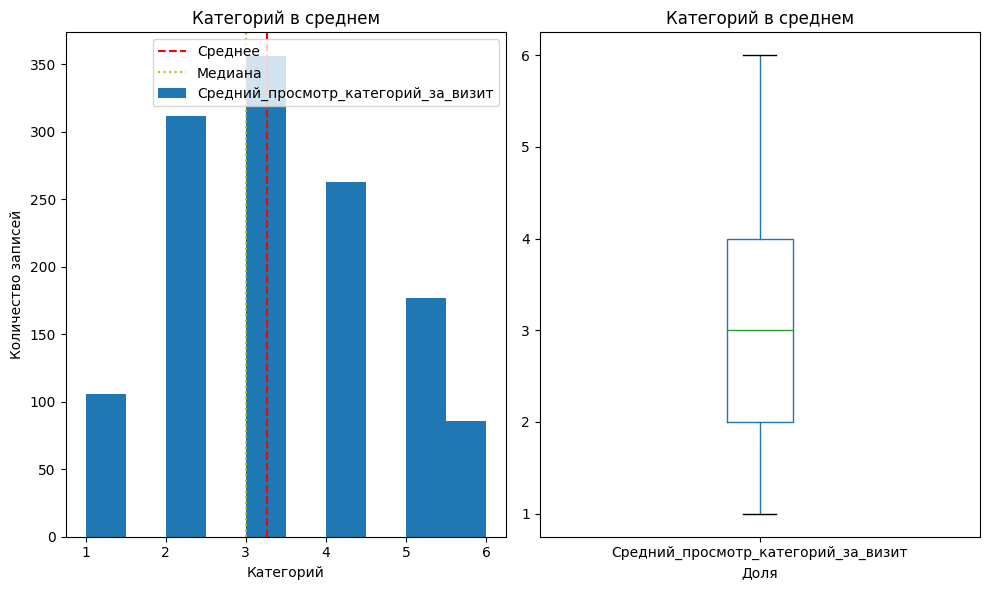

In [95]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Средний_просмотр_категорий_за_визит'].plot(kind='hist', bins=10, ax=ax1)
ax1.set_title('Категорий в среднем')
ax1.set_xlabel('Категорий')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Средний_просмотр_категорий_за_визит'].mean()
median_value = market_file['Средний_просмотр_категорий_за_визит'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Средний_просмотр_категорий_за_визит'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Категорий в среднем')
ax2.set_xlabel('Доля')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределение является мультимодальным с несколькими пиками.
<br/>
<br/>
    Основные пики находятся на значениях 2, 3 и 4.
<br/>
<br/>
    Среднее значение (красная пунктирная линия) находится около 3.
<br/>
<br/>
    Медиана (желтая пунктирная линия) также находится около 3, что говорит о том, что половина пользователей просматривает 3 или меньше категорий за визит.
<br/>
<br/>
    Каких-либо значительных выбросов не наблюдается.
</div>

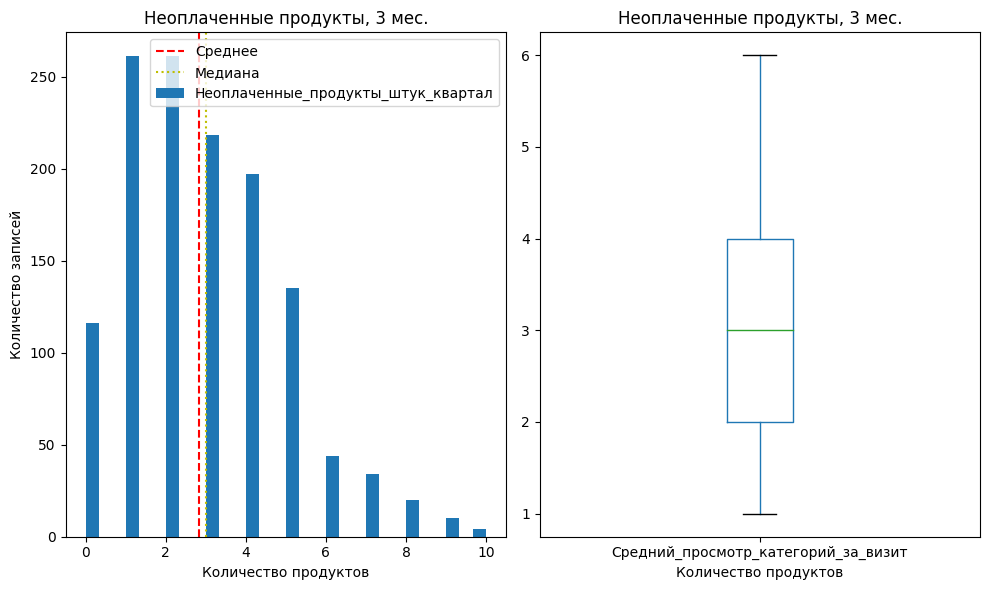

In [96]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Неоплаченные_продукты_штук_квартал'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Неоплаченные продукты, 3 мес.')
ax1.set_xlabel('Количество продуктов')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Неоплаченные_продукты_штук_квартал'].mean()
median_value = market_file['Неоплаченные_продукты_штук_квартал'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Средний_просмотр_категорий_за_визит'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Неоплаченные продукты, 3 мес.')
ax2.set_xlabel('Количество продуктов')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределение является правосторонне асимметричным (положительная асимметрия).
<br/>
<br/>
    Большинство пользователей имеют от 0 до 4 неоплаченных продуктов.
<br/>
<br/>
    Среднее значение (красная пунктирная линия) находится около 2-3.
<br/>
<br/>
    Медиана (желтая пунктирная линия) находится около 2, что говорит о том, что половина пользователей имеют 2 или меньше неоплаченных продуктов
</div>

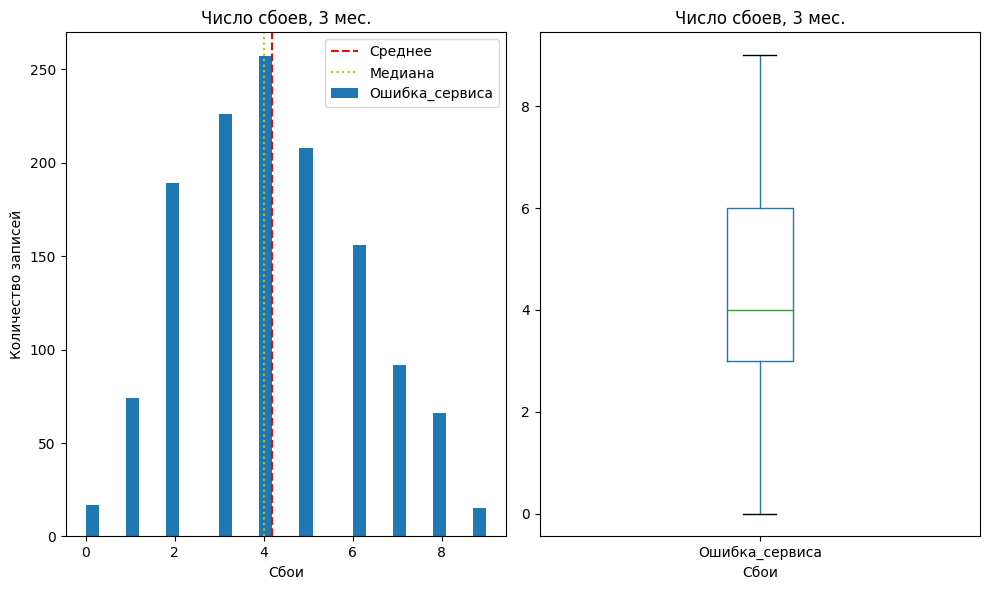

In [97]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Ошибка_сервиса'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Число сбоев, 3 мес.')
ax1.set_xlabel('Сбои')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Ошибка_сервиса'].mean()
median_value = market_file['Ошибка_сервиса'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Ошибка_сервиса'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Число сбоев, 3 мес.')
ax2.set_xlabel('Сбои')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределение является правосторонне асимметричным (положительная асимметрия).
<br/>
<br/>
    Большинство пользователей испытывают от 2 до 6 сбоев.
<br/>
<br/>
    Среднее значение (красная пунктирная линия) находится около 4.
<br/>
<br/>
    Медиана (желтая пунктирная линия) также находится около 4, что говорит о том, что половина пользователей испытывают 4 или меньше сбоев.
</div>

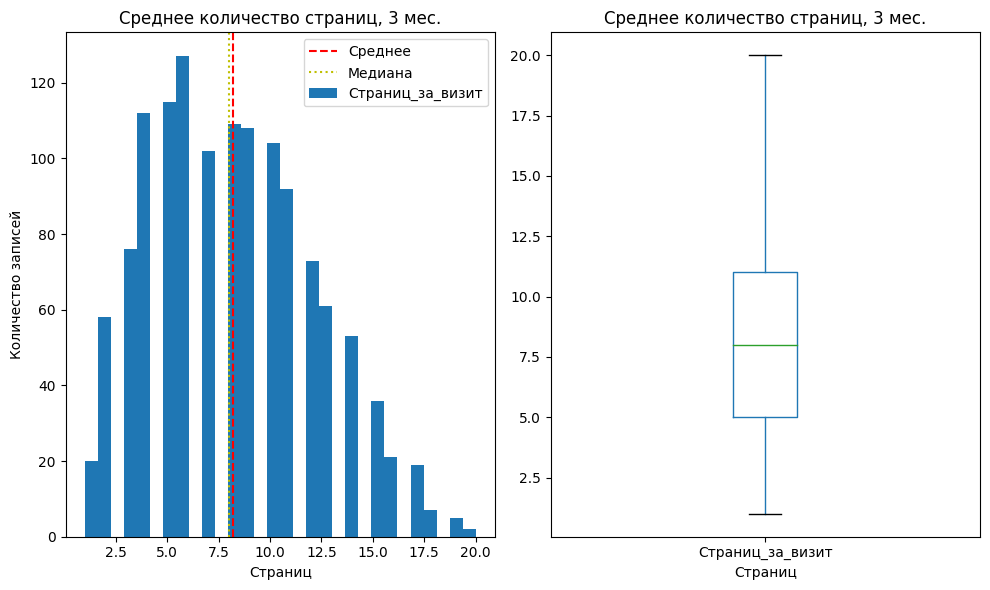

In [98]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Страниц_за_визит'].plot(kind='hist', bins=30, ax=ax1)
ax1.set_title('Среднее количество страниц, 3 мес.')
ax1.set_xlabel('Страниц')
ax1.set_ylabel('Количество записей')

mean_value = market_file['Страниц_за_визит'].mean()
median_value = market_file['Страниц_за_визит'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_file['Страниц_за_визит'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Среднее количество страниц, 3 мес.')
ax2.set_xlabel('Страниц')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределение является близким к нормальному, но с небольшой правосторонней асимметрией.
<br/>
<br/>
    Большинство пользователей просматривают от 5 до 12 страниц за визит.
<br/>
<br/>
    Среднее значение (красная пунктирная линия) находится около 9 страниц.
<br/>
<br/>
    Медиана (желтая пунктирная линия) также находится около 9 страниц, что говорит о том, что половина пользователей просматривает 9 или меньше страниц за визит.
</div>

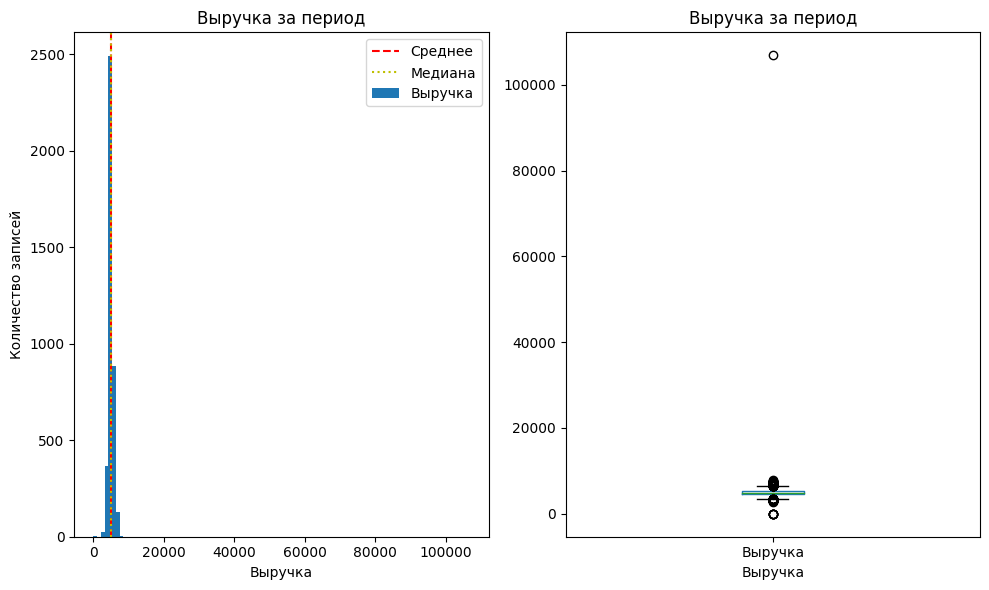

In [99]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_money['Выручка'].plot(kind='hist', bins=100, ax=ax1)
ax1.set_title('Выручка за период')
ax1.set_xlabel('Выручка')
ax1.set_ylabel('Количество записей')

mean_value = market_money['Выручка'].mean()
median_value = market_money['Выручка'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_money['Выручка'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Выручка за период')
ax2.set_xlabel('Выручка')

plt.tight_layout()
plt.show()

In [100]:
IQR = market_money['Выручка'].quantile(0.75) - market_money['Выручка'].quantile(0.25)
bottom = market_money['Выручка'].quantile(0.25) - IQR * 2
upper = market_money['Выручка'].quantile(0.75) + IQR * 2
display(market_money[(market_money['Выручка'] < bottom) | (market_money['Выручка'] > upper)].sort_values(by='Выручка'))

,id,Период,Выручка
0,215348,предпредыдущий_месяц,0.0
2,215348,предыдущий_месяц,0.0
28,215357,предпредыдущий_месяц,0.0
29,215357,предыдущий_месяц,0.0
34,215359,предыдущий_месяц,0.0
35,215359,предпредыдущий_месяц,0.0
356,215466,текущий_месяц,2758.7
649,215564,предыдущий_месяц,2890.0
662,215568,предыдущий_месяц,2909.0
2485,216176,текущий_месяц,2952.2


<div style="background-color: white; color: olive;">
    У нас исследование активных пользователей, так что если пользователь производит ноль выручки он для нас эквивалентен пустой записи. Ну, и 106862.2 у.е. выручки - явный выброс.
</div>

In [101]:
market_money = market_money.drop(market_money[(market_money['Выручка'] == 0) | (market_money['Выручка'] > 10000)].index)

<div style="background-color: white; color: olive;">
    Распределение является сильно правосторонне асимметричным (положительная асимметрия).
<br/>
<br/>
Большинство значений выручки сосредоточено около нуля, что говорит о том, что у большинства пользователей выручка очень мала.
<br/>
<br/>
Среднее значение (красная пунктирная линия) находится значительно правее основной массы данных, что характерно для правосторонней асимметрии.
<br/>
<br/>
Медиана (желтая пунктирная линия) находится около нуля, что говорит о том, что половина пользователей имеют очень низкую выручку.
</div>

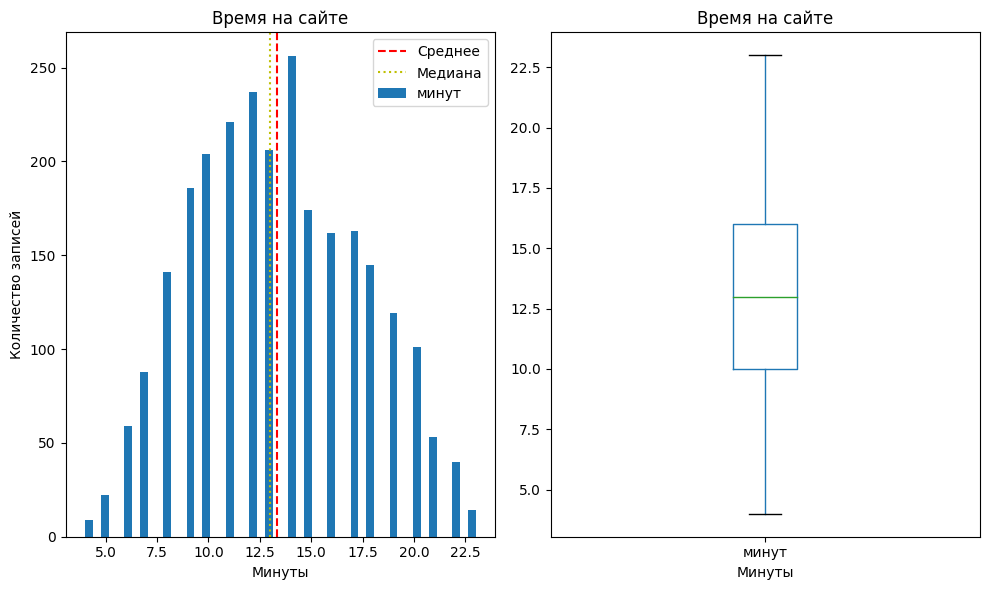

In [102]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_time['минут'].plot(kind='hist', bins=50, ax=ax1)
ax1.set_title('Время на сайте')
ax1.set_xlabel('Минуты')
ax1.set_ylabel('Количество записей')

mean_value = market_time['минут'].mean()
median_value = market_time['минут'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

market_time['минут'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Время на сайте')
ax2.set_xlabel('Минуты')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
Распределение близко к нормальному, но с небольшой правосторонней асимметрией.
<br/>
<br/>
Большинство пользователей проводят на сайте от 7.5 до 17.5 минут.
<br/>
<br/>
Среднее значение (красная пунктирная линия) находится около 12.5 минут.
<br/>
<br/>
Медиана (желтая пунктирная линия) также находится около 12 минут, что говорит о том, что половина пользователей проводит на сайте 12 или меньше минут.
</div>

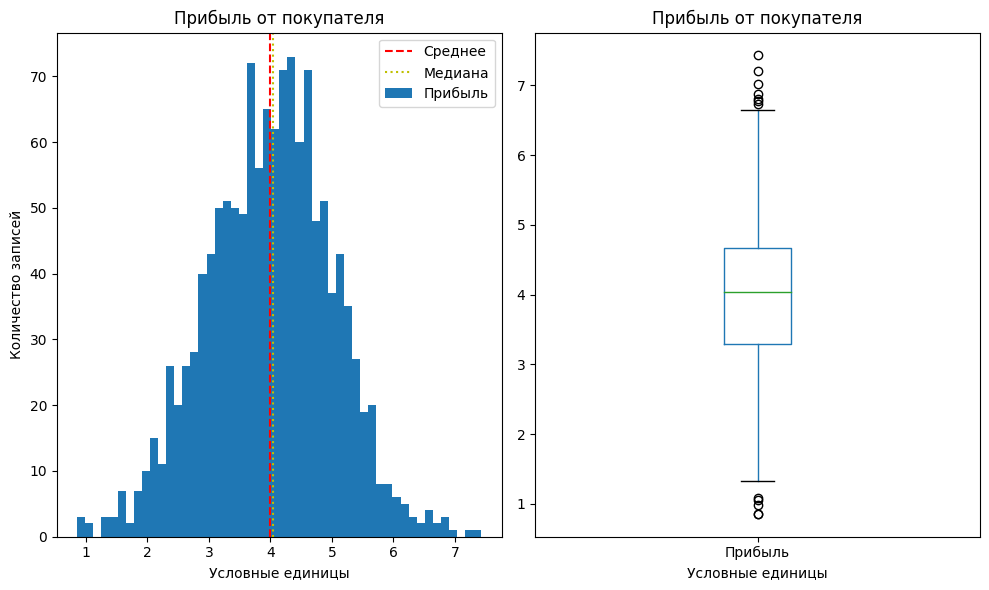

In [103]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

money['Прибыль'].plot(kind='hist', bins=50, ax=ax1)
ax1.set_title('Прибыль от покупателя')
ax1.set_xlabel('Условные единицы')
ax1.set_ylabel('Количество записей')

mean_value = money['Прибыль'].mean()
median_value = money['Прибыль'].median()

ax1.axvline(mean_value, color='r', linestyle='--', label='Среднее')
ax1.axvline(median_value, color='y', linestyle=':', label='Медиана')
ax1.legend()

money['Прибыль'].plot(kind='box', vert=True, ax=ax2)
ax2.set_title('Прибыль от покупателя')
ax2.set_xlabel('Условные единицы')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределение похоже на нормальное (колоколообразное), но с небольшой асимметрией вправо.
<br/>
<br/>
    Видно, что большинство значений прибыли сосредоточено в диапазоне от 2 до 6 условных единиц.
<br/>
<br/>
    Имеются выбросы, особенно в области высоких значений прибыли.
</div>

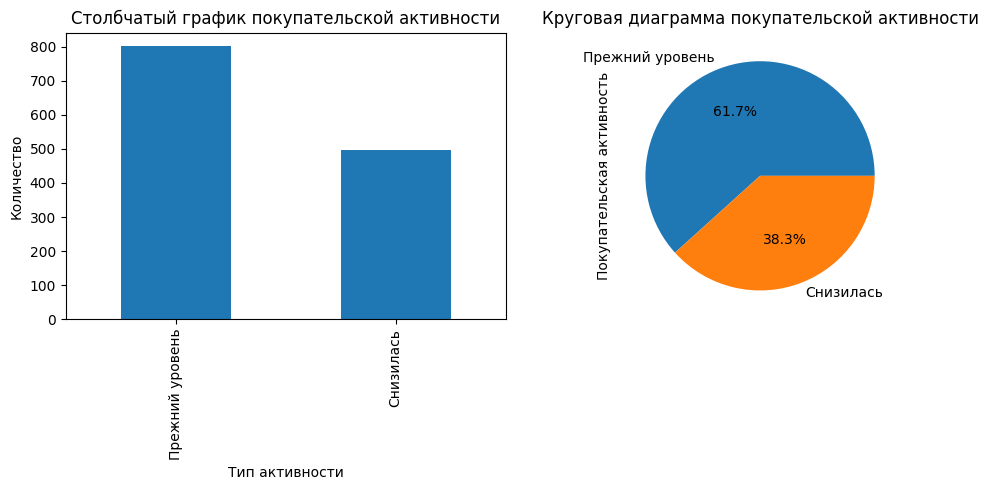

In [104]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

market_file['Покупательская активность'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Столбчатый график покупательской активности')
ax1.set_xlabel('Тип активности')
ax1.set_ylabel('Количество')

market_file['Покупательская активность'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Круговая диаграмма покупательской активности')

plt.tight_layout()
plt.show()

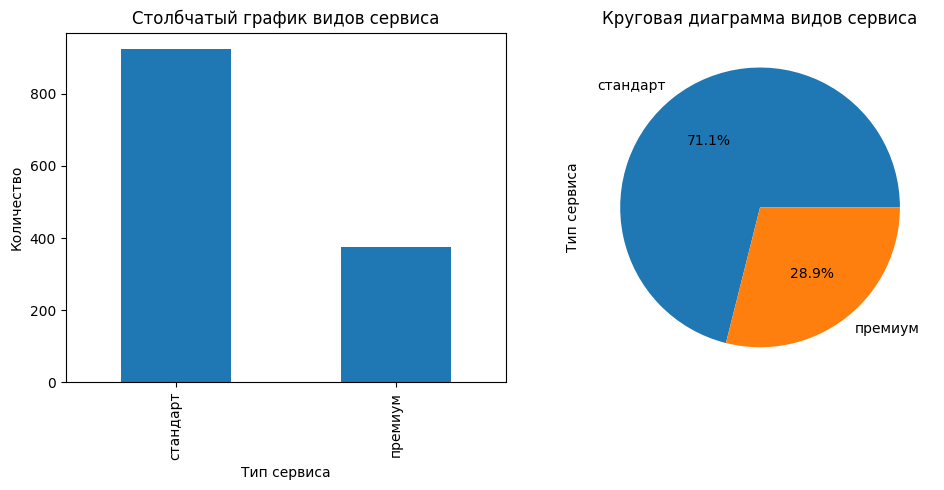

In [105]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

market_file['Тип сервиса'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Столбчатый график видов сервиса')
ax1.set_xlabel('Тип сервиса')
ax1.set_ylabel('Количество')

market_file['Тип сервиса'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Круговая диаграмма видов сервиса')

plt.tight_layout()
plt.show()

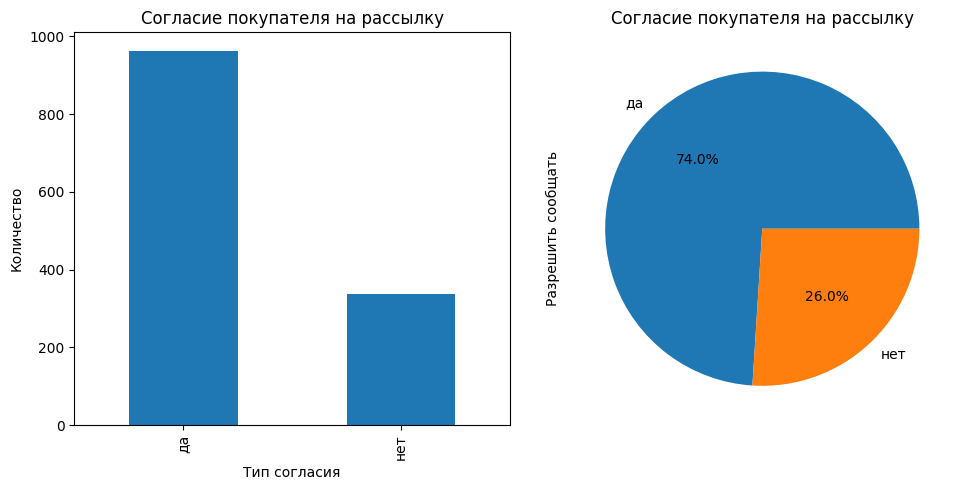

In [106]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

market_file['Разрешить сообщать'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Согласие покупателя на рассылку')
ax1.set_xlabel('Тип согласия')
ax1.set_ylabel('Количество')

market_file['Разрешить сообщать'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Согласие покупателя на рассылку')

plt.tight_layout()
plt.show()

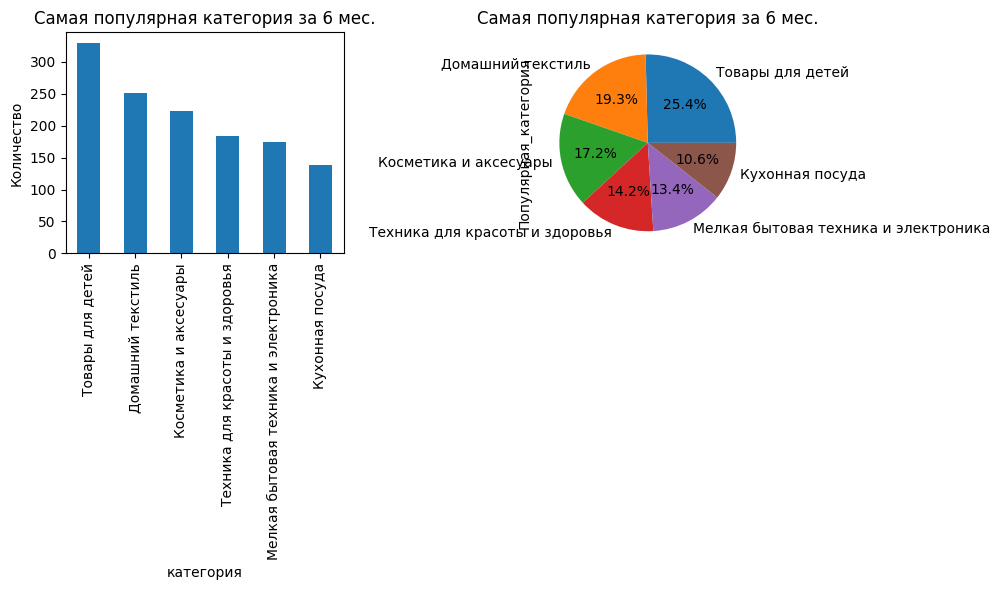

In [107]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

market_file['Популярная_категория'].value_counts().plot(kind='bar', ax=ax1)
ax1.set_title('Самая популярная категория за 6 мес.')
ax1.set_xlabel('категория')
ax1.set_ylabel('Количество')

market_file['Популярная_категория'].value_counts().plot(kind='pie', ax=ax2, autopct='%1.1f%%')
ax2.set_title('Самая популярная категория за 6 мес.')

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Теперь нам необходимо отобрать отдельно пользователей с покупательской активностью не менее 3-х месяцев.
</div>

In [108]:
filtered_users = (
    market_money[market_money['Выручка'] > 0]
    .groupby('id')['Период']
    .apply(lambda x: set(['текущий_месяц', 'предыдущий_месяц', 'предпредыдущий_месяц']).issubset(x.unique()))
)

active_users = filtered_users[filtered_users].index.tolist()

market_money['активный_пользователь'] = False

market_money.loc[market_money['id'].isin(active_users), 'активный_пользователь'] = True

display(market_money['активный_пользователь'].head(10))

1     False
3      True
4      True
5      True
6      True
7      True
8      True
9      True
10     True
11     True
Name: активный_пользователь, dtype: bool

<div style="background-color: white; color: olive;">
    В датасете market_money у нас появился новый столбец. Мы должны теперь подумать над выводами.
</div>

In [109]:
display(market_money['активный_пользователь'].sum() / len(market_money['активный_пользователь']))

0.9987156434626252

<div style="background-color: white; color: crimson;">
    Многие данные распределены ассиметрично или мультимодально, что говорит о том, что нам потребуется использовать корреляцию Фи. Местами имеются выбросы, большинство пользователей, о которых есть данные за три месяца в датасете market_money, являются активными, т.е. покупали что-либо в каждый из трёх прошедших месяцев.
</div>

In [110]:
display(market_time.head(10))

,id,Период,минут
0,215348,текущий_месяц,14
1,215348,предыдущий_месяц,13
2,215349,текущий_месяц,10
3,215349,предыдущий_месяц,12
4,215350,текущий_месяц,13
5,215350,предыдущий_месяц,8
6,215351,текущий_месяц,13
7,215351,предыдущий_месяц,11
8,215352,текущий_месяц,11
9,215352,предыдущий_месяц,8


## Объединение таблиц

In [111]:
# Объединение таблиц
merged_data = pd.merge(market_file, market_money, on='id', how='left')
merged_data = pd.merge(merged_data, market_time, on='id', how='left')

# Преобразование данных о выручке
pivot_revenue = merged_data.pivot_table(index='id', columns='Период_x', values='Выручка').reset_index()
revenue_columns = ['id'] + [f'выручка_{col}' for col in pivot_revenue.columns[1:]]
pivot_revenue.columns = revenue_columns

# Преобразование данных о времени
pivot_time = merged_data.pivot_table(index='id', columns='Период_y', values='минут').reset_index()
time_columns = ['id'] + [f'время_{col}' for col in pivot_time.columns[1:]]
pivot_time.columns = time_columns

# Объединение преобразованных данных
final_data = pd.merge(market_file, pivot_revenue, on='id', how='left')
final_data = pd.merge(final_data, pivot_time, on='id', how='left')

# Показать результат
display(final_data.head())

,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит,выручка_предпредыдущий_месяц,выручка_предыдущий_месяц,выручка_текущий_месяц,время_предыдущий_месяц,время_текущий_месяц
0,215348,Снизилась,премиум,да,3.4,5,121,0.00,Товары для детей,6,2,1,5,NaN,NaN,3293.1,13,14
1,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5,4472.0,5216.0,4971.6,12,10
2,215350,Снизилась,стандарт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5,4826.0,5457.5,5058.4,8,13
3,215351,Снизилась,стандарт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4,4793.0,6158.0,6610.4,11,13
4,215352,Снизилась,стандарт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2,4594.0,5807.5,5872.5,8,11


## Корреляционный анализ

interval columns not set, guessing: ['Маркет_актив_6_мес', 'Маркет_актив_тек_мес', 'Длительность', 'Акционные_покупки', 'Средний_просмотр_категорий_за_визит', 'Неоплаченные_продукты_штук_квартал', 'Ошибка_сервиса', 'Страниц_за_визит', 'выручка_предпредыдущий_месяц', 'выручка_предыдущий_месяц', 'выручка_текущий_месяц', 'время_предыдущий_месяц', 'время_текущий_месяц']


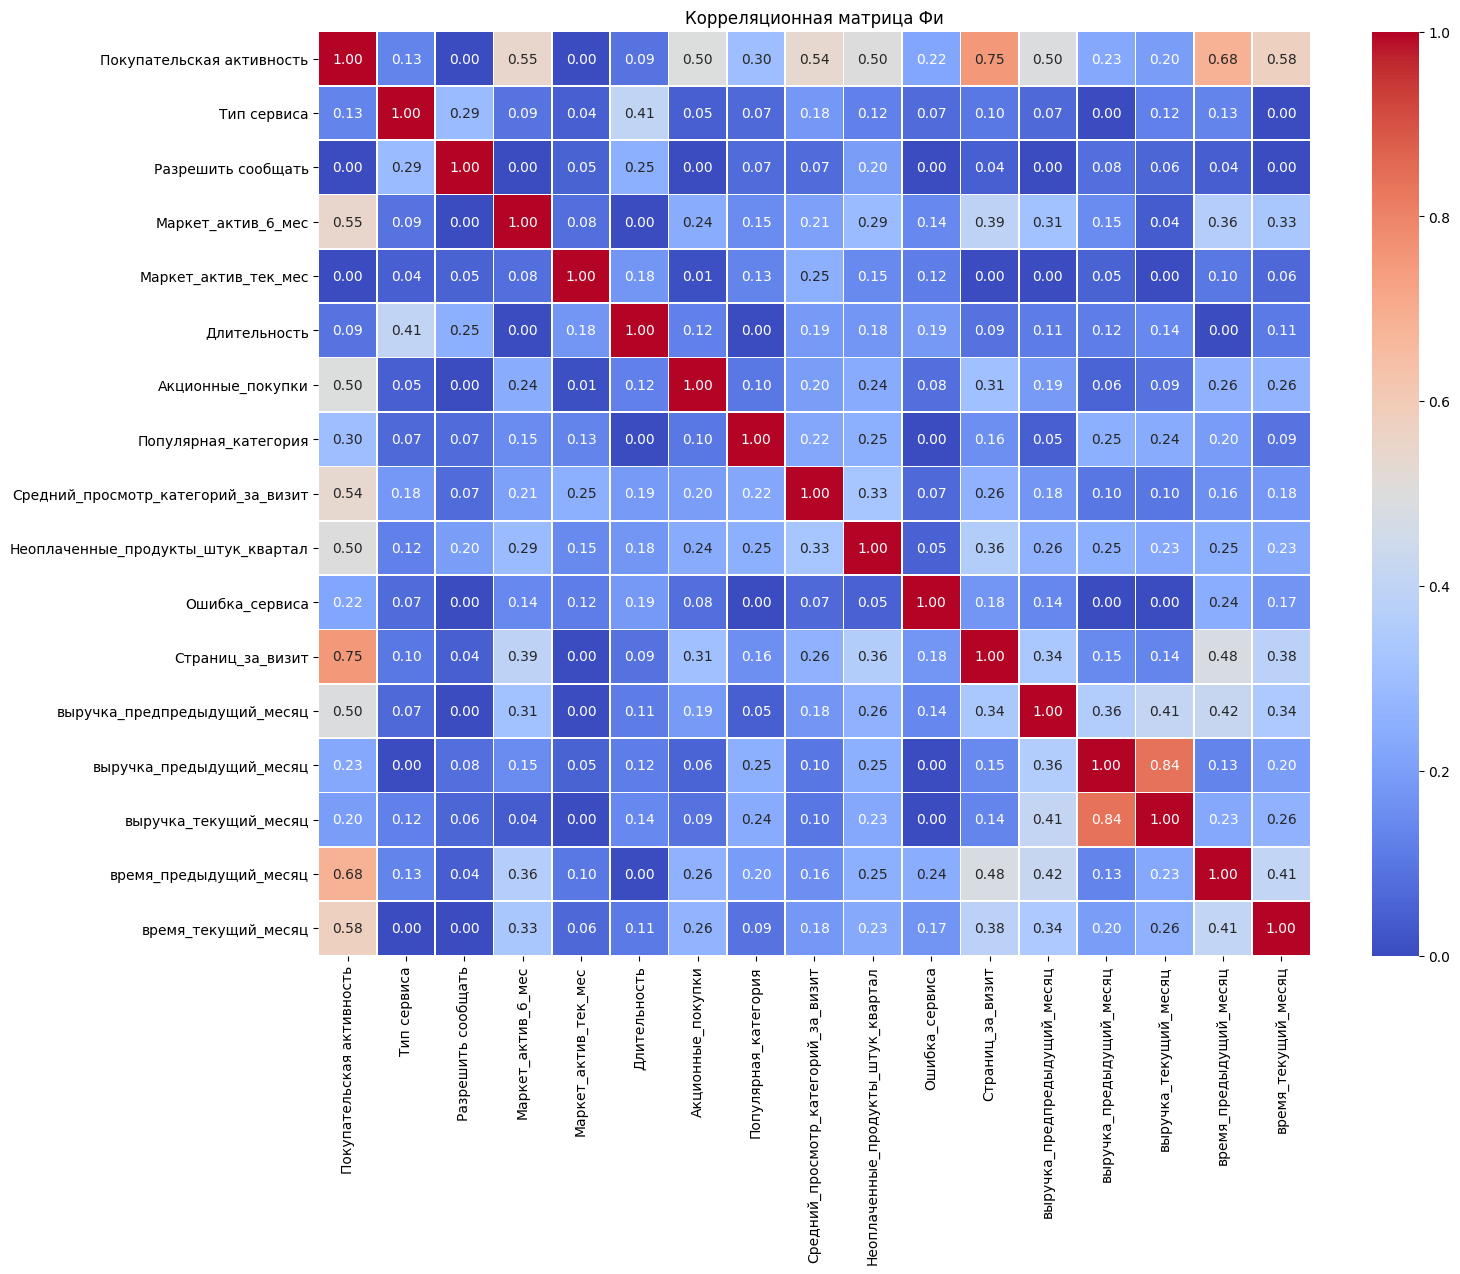

Пары признаков со значимой корреляцией:
Страниц_за_визит и Покупательская активность: 0.75
выручка_текущий_месяц и выручка_предыдущий_месяц: 0.84
время_предыдущий_месяц и Покупательская активность: 0.68


In [112]:
# Исключаем столбец 'id'
quantitative_data = final_data.drop('id', axis=1)

# Вычисляем корреляционную матрицу Фи
phik_corr_matrix = quantitative_data.phik_matrix()

# Визуализация корреляционной матрицы
plt.figure(figsize=(16, 12))
sns.heatmap(phik_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляционная матрица Фи')
plt.show()

# Анализ мультиколлинеарности
high_corr_pairs = []
for i in range(len(phik_corr_matrix.columns)):
    for j in range(i):
        if abs(phik_corr_matrix.iloc[i, j]) > 0.6:
            pair = (phik_corr_matrix.columns[i], phik_corr_matrix.columns[j], phik_corr_matrix.iloc[i, j])
            high_corr_pairs.append(pair)

print("Пары признаков со значимой корреляцией:")
for pair in high_corr_pairs:
    print(f"{pair[0]} и {pair[1]}: {pair[2]:.2f}")


<div style="background-color: white; color: olive;">
    Что же с мультиколлинеарностью? Есть явнная корреляция двух выручек: за предыдущий месяц и за предпредыдущий месяц, и они оба сильно коррелируют ещё и с акционными покупками. Видимо (посмею предположить), в предпредыдущий месяц былии введены масштабные акции, что продлились частично и на предыдущий месяц, что объясняет более сильную взаимосвязь акционных покупок с выручкой за предпредыдущий месяц, нежели с выручкой за предыдущий.
</div>

## Использование пайплайнов

<div style="background-color: white; color: olive;">
    Теперь перейдём к ужасному зверю по имени пайплайн, кем бы он ни был.
</div>

<div style="background-color: white; color: olive;">
    Так, теперь разобьём всё наше богатство на количественные и категориальные. Но для начала мы выделим целевую переменную и сделаем её бинарной. Перенесём id в индексы, чтобы после было удобнее работать с сегментацией пользователей.
</div>

In [113]:
final_data = final_data.set_index('id')

In [114]:
final_data['покупательская_активность_бинарная'] = final_data['Покупательская активность'].apply(lambda x: 1 if x == 'Снизилась' else 0)

numerical_features = final_data.drop(
    columns=[
        'покупательская_активность_бинарная'
    ]
).select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = final_data.drop(
    columns=['Покупательская активность']
).select_dtypes(include=['object']).columns.tolist()

<div style="background-color: white; color: olive;">
    А на этом шаге мы создадим объединённые преобразоватор категориальных и количественных признаков.
</div>

In [115]:
# Преобразуем количественные признаки
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Заполнение пропусков
    ('scaler', StandardScaler())  # Стандартизация
])

# Преобразуем категориальные признаки с OneHotEncoder (для линейных моделей)
categorical_transformer_ohe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Заполнение пропусков
    ('encoder', OneHotEncoder(drop='first', handle_unknown='error'))  # Кодирование с дропом первой категории
])

# Преобразуем категориальные признаки с OrdinalEncoder (для деревьев)
categorical_transformer_oe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Заполнение пропусков
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))  # Кодирование в числовые значения
])

# Объединяем трансформации для числовых и категориальных признаков
preprocessor_ohe = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer_ohe, categorical_features)
    ]
)

preprocessor_oe = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer_oe, categorical_features)
    ]
)

<div style="background-color: white; color: olive;">
    Теперь к нашему препроцессору добавим четыре разщные модели: KNeighborsClassifier(), DecisionTreeClassifier(), LogisticRegression() и SVC(). И подберём гиперпараметры с учётом accuracy.
</div>

<div style="background-color: white; color: olive;">
    Т.к. нам важно различать классы (не будет активным / будет активным) и у нас есть явный дисбаланс активных и неактивных пользователей, оптимальной метрикой будет roc_auc. Так что за счёт универсальности и возможности сравнивать модели по качеству разделения классов я выбираю данную метрику. F1 также полезен при несбалансированных классах. В использовании тут помимо них precision и recall я не столь уверен, т.к. это делает для нас критичными и ложноположительные, и ложноотрицательные ошибки.
</div>

In [116]:
# Определяем метрики
scoring = {
    'roc_auc': 'roc_auc',
    'f1': make_scorer(f1_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score)
}

# Пайплайн для KNN с OneHotEncoder
pipeline_knn = Pipeline(steps=[
    ('preprocessor', preprocessor_ohe),
    ('classifier', KNeighborsClassifier())
])

# Пайплайн для DecisionTree с OrdinalEncoder и фиксированным random_state
pipeline_dt = Pipeline(steps=[
    ('preprocessor', preprocessor_oe),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        max_depth=10,
        min_samples_split=5
    ))
])

# Пайплайн для LogisticRegression с OneHotEncoder и фиксированным random_state
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor_ohe),
    ('classifier', LogisticRegression(random_state=42))
])

# Пайплайн для SVC с OneHotEncoder и фиксированным random_state
pipeline_svc = Pipeline(steps=[
    ('preprocessor', preprocessor_ohe),
    ('classifier', SVC(random_state=42, probability=True))
])

# Гиперпараметры для моделей
param_grid_knn = {
    'classifier__n_neighbors': [3, 5, 7]
}

param_grid_dt = {
    'classifier__max_depth': [3, 5, 7]
}

param_grid_lr = {
    'classifier__C': [0.1, 1, 10]
}

param_grid_svc = {
    'classifier__C': [0.1, 1, 10],
    'classifier__kernel': ['rbf', 'linear']
}

# Подбор гиперпараметров с несколькими метриками
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=5, scoring=scoring, refit='roc_auc')
grid_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=5, scoring=scoring, refit='roc_auc')
grid_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, scoring=scoring, refit='roc_auc')
grid_svc = GridSearchCV(pipeline_svc, param_grid_svc, cv=5, scoring=scoring, refit='roc_auc')

<div style="background-color: white; color: olive;">
    А на этом шаге выделим множества с независимыми и целевой переменными. Причём важно, чтобы в обеих выборка были как нули, так и единички в целевой переменной, поэтому используем stratify=y.
</div>

In [117]:
X = final_data.drop(
    columns=[
        'покупательская_активность_бинарная',
        'Покупательская активность'
    ]
)

y = final_data['покупательская_активность_бинарная']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(y_train.value_counts())
print(y_test.value_counts())

0    642
1    398
Name: покупательская_активность_бинарная, dtype: int64
0    160
1    100
Name: покупательская_активность_бинарная, dtype: int64


<div style="background-color: white; color: olive;">
    Время обучать модели!
</div>

In [118]:
grid_knn.fit(X_train, y_train)
grid_dt.fit(X_train, y_train)
grid_lr.fit(X_train, y_train)
grid_svc.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Маркет_актив_6_мес',
                                                                          'Маркет_актив_тек_мес',
                                                                          'Длительность',
                                                                          'Акционные_покупки',
                             

In [119]:
y_train_proba_svc = grid_svc.best_estimator_.predict_proba(X_train)[:, 1]
y_test_proba_svc = grid_svc.best_estimator_.predict_proba(X_test)[:, 1]

In [120]:
# Определяем лучшую модель по значению best_score_
best_models = {
    'KNN': (grid_knn.best_score_, grid_knn.best_estimator_),
    'Decision Tree': (grid_dt.best_score_, grid_dt.best_estimator_),
    'Logistic Regression': (grid_lr.best_score_, grid_lr.best_estimator_),
    'SVC': (grid_svc.best_score_, grid_svc.best_estimator_)
}

# Находим модель с наибольшим best_score_
best_model_name, (best_score, best_estimator) = max(best_models.items(), key=lambda x: x[1][0])
print(f"Лучшая модель: {best_model_name} с best_score: {best_score}")

# Выводим параметры лучшей модели
print('Лучшая модель и её параметры:\n\n', best_estimator)

# Предсказываем вероятности для тестового набора данных
y_test_proba = best_estimator.predict_proba(X_test)[:, 1]

# Предсказываем классы для тестового набора данных
y_test_pred = best_estimator.predict(X_test)

# Рассчитываем метрики на тестовом наборе данных
roc_auc = roc_auc_score(y_test, y_test_proba)
f1 = f1_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)

print(f"ROC AUC на тестовом наборе: {roc_auc}")
print(f"F1 на тестовом наборе: {f1}")
print(f"Precision на тестовом наборе: {precision}")
print(f"Recall на тестовом наборе: {recall}")

Лучшая модель: SVC с best_score: 0.9215566622816702
Лучшая модель и её параметры:

 Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Маркет_актив_6_мес',
                                                   'Маркет_актив_тек_мес',
                                                   'Длительность',
                                                   'Акционные_покупки',
                                                   'Средний_просмотр_категорий_за_визит',
                                                   'Неоплаченные_продукты_штук_квартал',
               

<div style="background-color: black; color: #FFA500;">
    Модель SVC показывает отличные результаты по большинству метрик.
<br/>
ROC AUC (0.8936) и Precision (0.9136) особенно высокие, что говорит о хорошей способности модели различать классы и низкой доле ложноположительных ошибок.
<br/>
Recall (0.74) несколько ниже, что может означать, что модель иногда пропускает положительные случаи.
</div>

<div style="background-color: white; color: olive;">
    Лучшей оценкой у нас обладает модель SVC, так что продолжим работу с ней.
</div>

## Анализ важности признаков

<div style="background-color: white; color: olive;">
    Теперь используем SHAP (это метод объяснения предсказаний моделей машинного обучения, основанный на теории игр. Он помогает понять, как каждый признак влияет на предсказание модели):
<br/>
<br/>
    1) Получим обучающие данные после предобработки;
<br/>   
    2) Уменьшим количество фоновых данных при помощи k-means (используем кластеризацию k-means для уменьшения количества фоновых данных, сохраняя при этом их разнообразие)
<br/>
    3) Создадим объяснитель SHAP (это инструмент, который вычисляет SHAP значения для модели и данных);
<br/>
    4) Вычислим значения SHAP для тестовой выборки;
<br/>
    5) Затем получим имена признаков после предобработки;
<br/>
    6) И визуализируем их важность.
</div>

In [ ]:
# Используем лучшую модель из grid_svc (включая её препроцессор)
best_svc_estimator = grid_svc.best_estimator_

# Получаем обученный препроцессор из лучшей модели
preprocessor = best_svc_estimator.named_steps['preprocessor']

# Получаем обученный классификатор из лучшей модели
svc_classifier = best_svc_estimator.named_steps['classifier']

# Получаем обучающие данные после предобработки с использованием препроцессора из лучшей модели
X_train_processed = preprocessor.transform(X_train)

# Уменьшаем количество фоновых данных
background = shap.sample(X_train_processed, 100)  # Используем 100 фоновых примеров

# Создаем объяснитель SHAP с использованием KernelExplainer
explainer = shap.KernelExplainer(svc_classifier.predict_proba, background)

# Получаем тестовые данные после предобработки с использованием препроцессора из лучшей модели
X_test_processed = preprocessor.transform(X_test)  # Используем preprocessor, а не svc_pipeline

# Вычисляем значения SHAP для тестовой выборки
shap_values = explainer.shap_values(X_test_processed)

# Выбираем SHAP-значения для второго класса (индекс 1)
shap_values_class_1 = shap_values[..., 1]  # или shap_values[1]

# Получаем имена числовых признаков
numerical_feature_names = X_train[numerical_features].columns.tolist()

# Получаем имена закодированных категориальных признаков
onehot_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']  # Используем preprocessor

if hasattr(onehot_encoder, 'get_feature_names_out'):
    categorical_feature_names = onehot_encoder.get_feature_names_out(categorical_features)
elif hasattr(onehot_encoder, 'get_feature_names'):
    categorical_feature_names = onehot_encoder.get_feature_names(categorical_features)
else:
    raise AttributeError("The OneHotEncoder does not have get_feature_names or get_feature_names_out method.")

# Объединяем имена всех признаков
feature_names = numerical_feature_names + list(categorical_feature_names)

# Проверка размерностей
print(f"Number of features in shap_values_class_1: {shap_values_class_1.shape[1]}")
print(f"Number of features in X_test_processed: {X_test_processed.shape[1]}")
print(f"Number of feature names: {len(feature_names)}")


  0%|          | 0/260 [00:00<?, ?it/s]

In [ ]:
# Получаем средние значения SHAP для каждого признака
mean_shap_values = np.abs(shap_values_class_1).mean(axis=0)

# Сортируем признаки по убыванию важности
sorted_idx = np.argsort(mean_shap_values)[::-1]
sorted_mean_shap_values = mean_shap_values[sorted_idx]
sorted_feature_names = np.array(feature_names)[sorted_idx]

# Ограничиваем количество отображаемых признаков
max_display = 20
sorted_mean_shap_values = sorted_mean_shap_values[:max_display]
sorted_feature_names = sorted_feature_names[:max_display]

# Нормализуем значения SHAP для увеличения длины красных полосок
scale_factor = 2.5
scaled_shap_values = sorted_mean_shap_values * scale_factor

# Создаем график
fig, ax = plt.subplots(figsize=(10, 8))

# Важность признаков красным
ax.barh(np.arange(max_display), scaled_shap_values, color='red', height=0.6)

# Настройки осей и меток
ax.set_yticks(np.arange(max_display))
ax.set_yticklabels(sorted_feature_names)
ax.set_xlabel('Важность признаков (mean(|SHAP value|))')
ax.set_title('Важность признаков')

# Убираем рамку
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# Используем уже отсортированные данные из предыдущей ячейки кода
max_display = 20
shap_values_sorted = shap_values[:, sorted_idx[:max_display]]
sorted_feature_names = sorted_feature_names[:max_display]

# Подготавливаем данные X_test_processed с нужными признаками
X_test_processed_sorted = X_test_processed[:, sorted_idx[:max_display]]

# Создаем график с увеличенной шириной (снова у меня траблы с пропорциями графика)
shap.summary_plot(
    shap_values_sorted,
    X_test_processed_sorted,
    feature_names=sorted_feature_names,
    plot_type="dot",
    color="red",
    show=False,
    alpha=0.7,
    plot_size=(16, 10)
)

ax = plt.gca()
ax.tick_params(axis='y', labelsize=13)
ax.tick_params(axis='x', labelsize=11)
ax.set_xlabel('Значения SHAP')
ax.set_title('График важности признаков (Dot Plot)')

# У меня внизу почему-то создавался пустой график, это его фиксит:
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Итак, что же больше всего влияет на покупательскую активность (согласно нашей прекрасной моделе)? Это:
<br/>
<br/>
    1) Страниц_за_визит — среднее количество страниц, которые просмотрел покупатель за один визит на сайт за последние 3 месяца;
<br/>
    2) Время, проведённое пользователем на сайте, за предыдущий и текущий месяцы;
<br/>
    3) Акционные_покупки — среднемесячная доля покупок по акции от общего числа покупок за последние 6 месяцев;
<br/>
    4) Неоплаченные_продукты_штук_квартал — общее число неоплаченных товаров в корзине за последние 3 месяца;
<br/>
    5) Средний_просмотр_категорий_за_визит — показывает, сколько в среднем категорий покупатель просмотрел за визит в течение последнего месяца.
</div>

<div style="background-color: white; color: olive;">
    В общем, важно, чтобы пользователь как можно больше залипал на сайте, чтобы там были разные товары, куча акций, он добавлял как можно больше в корзину. В общем, сделать сайт нтернет-магазина «В один клик» более лудоманским, типа, раскрути колесо удачи на скидки! Два по цене одного! «Акция: при покупке шампуня "Драугр" лопата в подарок»! По крайней мере, на подобное поведение намекают наиболее влияющие на покупательскую активность факторы.
</div>

## Сегментация покупателей

<div style="background-color: black; color: #FFD700;">
    Следующим шагом необходимо выполнить сегментацию пользователей.
    <br/>
    <br/>
    Задача звучит следующим образом:
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;1) Выполните сегментацию покупателей. Используйте результаты моделирования и данные о прибыльности покупателей.
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;2) Выберите группу покупателей и предложите, как увеличить её покупательскую активность:
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Проведите графическое и аналитическое исследование группы покупателей.
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Сделайте предложения по работе с сегментом для увеличения покупательской активности.
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;3) Сделайте выводы о сегментах:
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;какой сегмент вы взяли для дополнительного исследования,
    <br/>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;какие предложения вы сделали и почему.
</div>

In [ ]:
#full_data = pd.merge(final_data, money, on='id')
#display(full_data.head(10))

<div style="background-color: white; color: olive;">
    Нам необходимо добавить к датафрейму два важных элемента:
<br/>
    <br/>
    1) Результаты моделирования
<br/>
    <br/>
    2) Данный о прибыльности.
<br/>
    <br/>
    Соответственно, сконцентрируемся на предсказаниях изменения активности покупателей. Напомню сам себе:
    final_data['покупательская_активность_бинарная'] = final_data['Покупательская активность'].apply(lambda x: 1 if x == 'Снизилась' else 0), т.е. 1 -- это снизилась, 0 -- не снизилась.
</div>

In [ ]:
X_test_new = X_test.copy()
X_train_new = X_train.copy()
X_test_new['вероятность_снижения_покупательской_активности'] = y_test_proba_svc
X_train_new['вероятность_снижения_покупательской_активности'] = y_train_proba_svc
data_predictions = pd.concat([X_test_new, X_train_new])

<div style="background-color: white; color: olive;">
    Теперь добавим и данные о выручке.
</div>

In [ ]:
money = money.set_index('id')

data_predictions_money = data_predictions.merge(
    money,
    left_index=True,
    right_index=True,  
    how='left'
)


In [ ]:
display(data_predictions_money.head(10))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Тип сервиса",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Тип сервиса")
plt.show()

<div style="background-color: white; color: olive;">
    Клиенты с премиум-типа и стандартного класса распределены по всему графику. Однако можно заметить, что среди высокоприбыльных клиентов больше тех, кто использует премиум-сервис (с поправкой на очевидную разницу в количественном наличии субъектов типа премиум и типа стандарт).
</div>

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Разрешить сообщать",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Разрешить сообщать")
plt.show()

<div style="background-color: white; color: olive;">
    Вот, о чём я подумал:
<br/>
    На диаграммах рассеяния лучше всего видно разбиение на группы в случае с категориальными переменными. Поэтому для столбцов "Маркет_актив_6_мес", "Маркет_актив_тек_мес", "Длительность", "Средний_просмотр_категорий_за_визит", "Неоплаченные_продукты_штук_квартал", "Ошибка_сервиса", "Страниц_за_визит" мы сделаем категориальную альтернативу: до медианы / больше медианы.
<br/>
    <br/>
    Для столбца "Акционные_покупки" сделаем чуть больше категорий, т.к. +/- как работают акции в Интернет-магазинах у меня есть бытовое понимание, мне интересно попробовать его переложить.
</div>

In [ ]:
def median_splitter(x, med):
    if x <= med:
        return 'не_превышает_медианы'
    else:
        return 'превышает_медиану'

med_market_6_months = data_predictions_money['Маркет_актив_6_мес'].median()
med_market_this_month = data_predictions_money['Маркет_актив_тек_мес'].median()
med_duration = data_predictions_money['Длительность'].median()
med_average_category_views_per_visit = data_predictions_money['Средний_просмотр_категорий_за_визит'].median()
med_unpaid_products = data_predictions_money['Неоплаченные_продукты_штук_квартал'].median()
med_service_errors = data_predictions_money['Ошибка_сервиса'].median()
med_pages_per_visit = data_predictions_money['Страниц_за_визит'].median()

data_predictions_money['Маркет_актив_6_мес_мед'] = data_predictions_money['Маркет_актив_6_мес'].apply(lambda x: median_splitter(x, med_market_6_months))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Маркет_актив_6_мес_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Маркет_актив_6_мес_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них не превышают медианную активность за последние 6 месяцев. Это может указывать на то, что низкая активность связана с высоким риском снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, особенно если они приносят высокую прибыль.
<br/>
    <br/>
        <br/>
Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них больше тех, кто превышает медианную активность. Это логично, так как высокая активность связана с низким риском снижения покупательской активности. Важно поддерживать их лояльность.
</div>

In [ ]:
data_predictions_money['Маркет_актив_тек_мес_мед'] = data_predictions_money['Маркет_актив_тек_мес'].apply(lambda x: median_splitter(x, med_market_this_month))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Маркет_актив_тек_мес_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Маркет_актив_тек_мес_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них не превышают медианную активность за текущий месяц. Это может указывать на то, что низкая текущая активность связана с высоким риском снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, особенно если они приносят высокую прибыль.
<br/>
    <br/>
        <br/>
Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них больше тех, кто превышает медианную активность. Это логично, так как высокая активность связана с низким риском снижения покупательской активности. Важно поддерживать их лояльность.
</div>

In [ ]:
data_predictions_money['Длительность_мед'] = data_predictions_money['Длительность'].apply(lambda x: median_splitter(x, med_duration))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Длительность_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Длительность_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них не превышают медианное время регистрации. Это может указывать на то, что более новые клиенты (с меньшей длительностью регистрации) имеют более высокий риск снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, особенно если они приносят высокую прибыль.
<br/>
    <br/>
        <br/>
Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них примерно равное количество клиентов с разной длительностью регистрации. Это может указывать на то, что длительность регистрации не так сильно влияет на вероятность снижения активности для этой группы.

</div>

In [ ]:
data_predictions_money['Средний_просмотр_категорий_за_визит_мед'] = data_predictions_money['Средний_просмотр_категорий_за_визит'].apply(lambda x: median_splitter(x, med_average_category_views_per_visit))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Средний_просмотр_категорий_за_визит_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Средний_просмотр_категорий_за_визит_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них не превышают медианное значение по среднему просмотру категорий за визит. Это может указывать на то, что низкая вовлечённость (меньшее количество просмотренных категорий) связана с высоким риском снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, особенно если они приносят высокую прибыль.
<br/>
    <br/>
        <br/>
Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них больше тех, кто превышает медианное значение по среднему просмотру категорий за визит. Это логично, так как высокая вовлечённость связана с низким риском снижения покупательской активности. Важно поддерживать их лояльность.
</div>

In [ ]:
data_predictions_money['Неоплаченные_продукты_штук_квартал_мед'] = data_predictions_money['Неоплаченные_продукты_штук_квартал'].apply(lambda x: median_splitter(x, med_unpaid_products))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Неоплаченные_продукты_штук_квартал_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Неоплаченные_продукты_штук_квартал_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них превышают медианное значение по количеству неоплаченных продуктов. Это может указывать на то, что большое количество неоплаченных продуктов связано с высоким риском снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, например, напоминания об оплате, скидки или персонализированные предложения.
<br/>
    <br/>
        <br/>

Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них примерно равное количество клиентов с разным количеством неоплаченных продуктов. Это может указывать на то, что количество неоплаченных продуктов не так сильно влияет на вероятность снижения активности для этой группы.
</div>

In [ ]:
data_predictions_money['Ошибка_сервиса_мед'] = data_predictions_money['Ошибка_сервиса'].apply(lambda x: median_splitter(x, med_service_errors))

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Ошибка_сервиса_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Ошибка_сервиса_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них превышают медианное значение по количеству ошибок сервиса. Это может указывать на то, что большое количество ошибок сервиса связано с высоким риском снижения покупательской активности. Возможно, стоит разработать стратегии для улучшения качества сервиса и устранения ошибок, чтобы удержать этих клиентов.
<br/>
    <br/>
        <br/>
    
Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них примерно равное количество клиентов с разным количеством ошибок сервиса. Это может указывать на то, что количество ошибок сервиса не так сильно влияет на вероятность снижения активности для этой группы.
</div>

In [ ]:
data_predictions_money['Страниц_за_визит_мед'] = data_predictions_money['Страниц_за_визит'].apply(lambda x: median_splitter(x, med_pages_per_visit))

<div style="background-color: white; color: olive;">
    
</div>

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Страниц_за_визит_мед",
    palette="cividis",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Страниц_за_визит_мед")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них не превышают медианное значение по количеству просмотренных страниц за визит. Это может указывать на то, что низкая вовлечённость (меньшее количество просмотренных страниц) связана с высоким риском снижения покупательской активности. Возможно, стоит разработать стратегии для увеличения вовлечённости этих клиентов, например, улучшение пользовательского опыта, персонализированные рекомендации и акции.
<br/>
    <br/>
        <br/>

Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них больше тех, кто превышает медианное значение по количеству просмотренных страниц за визит. Это логично, так как высокая вовлечённость связана с низким риском снижения покупательской активности. Важно поддерживать их лояльность.
</div>

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Популярная_категория",
    palette="plasma",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Популярная_категория")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Среди них много клиентов, предпочитающих "Мелкую бытовую технику и электронику" и "Косметику и аксессуары". Это может указывать на то, что клиенты, предпочитающие эти категории, имеют более высокий риск снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, например, персонализированные предложения и акции по данным категориям.
<br/>
    <br/>
        <br/>

Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них больше тех, кто предпочитает "Мелкую бытовую технику и электронику" и "Товары для детей". Это логично, так как эти категории могут быть более востребованы и иметь более лояльных клиентов. Важно поддерживать их лояльность.
</div>

<div style="background-color: white; color: olive;">
    А вот с акциями ("Акционные_покупки") всё сильно сложнее: дело в том, что зачастую на маркетплейсах или сайтах магазинов слишком много акций (да, 999 рублей вместо 1000 рублей тоже формально может быть акцией), а многие люди купят тот или иной товар вне зависимости от акций. К тому же, некоторые товары бывают на вечных акциях (они всегда стоят 1000 рублей, но у них красивый ценник, мол, 2000? Нет, 1000!). Таким образом, у человека в корзине всегда могут быть товары по акциям, даже если он их планировал купить вне зависимости от скидок. Думаю, что тут логичнее будет разбиение на квартили, где:
<br/>
    <br/>
    1) Первый квартиль = не обращает внимание на скидки
    <br/>
    2) Второй = обращает несущественное внимание на скидки
    <br/>
    3) Третий = обращает значимое внимание на скидки
    <br/>
    4) Четвёртый = ориентируется на скидки
</div>

In [ ]:
qq = data_predictions_money['Акционные_покупки'].quantile([0.25, 0.5, 0.75])
print(qq)

In [ ]:
def qq_sales(purchases_on_sale):
    if purchases_on_sale <= 0.17:
        return 'не_обращает_внимание_на_скидки'
    elif purchases_on_sale <= 0.24:
        return 'обращает_несущественное_внимание_на_скидки'
    elif purchases_on_sale <= 0.30:
        return 'обращает_значимое_внимание_на_скидки'
    else:
        return 'ориентируется_на_скидки'

In [ ]:
data_predictions_money['Акционные_покупки_кварт'] = data_predictions_money['Акционные_покупки'].apply(qq_sales)

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=data_predictions_money,
    x="вероятность_снижения_покупательской_активности",
    y="Прибыль",
    hue="Акционные_покупки_кварт",
    palette="plasma",
    alpha=0.75
)

plt.title("Зависимость вероятности снижения покупательской активности от прибыли")
plt.xlabel("Вероятность снижения покупательской активности")
plt.ylabel("Прибыль")
plt.legend(title="Акционные_покупки_кварт")
plt.show()

<div style="background-color: white; color: olive;">
Клиенты с высокой вероятностью снижения активности:
<br/>
    <br/>
Большинство из них обращают значимое внимание на скидки или ориентируются на них. Это может указывать на то, что клиенты, которые активно реагируют на скидки, имеют более высокий риск снижения покупательской активности. Возможно, стоит разработать стратегии удержания для этих клиентов, например, предлагать персонализированные скидки и акции.
<br/>
    <br/>
        <br/>

Клиенты с низкой вероятностью снижения активности:
<br/>
    <br/>
Среди них больше тех, кто не обращает внимание на скидки или обращает несущественное внимание. Это логично, так как такие клиенты могут быть более лояльными и менее чувствительными к изменениям цен. Важно поддерживать их лояльность.
</div>

<div style="background-color: black; color: #FFD700;">
    ОБОБЩАЮ!
<br/>
<br/>
    Более активные пользователи = больше денег;
<br/>
    Чем дольше удерживается пользователь активным с момента регистраци, тем лучше;
<br/>
    Чем больше категорий смотрят пользователи, тем лучше;
<br/>
    Крайне важны те, кто покупают и со скидками, и без оных;
<br/>
    "Мелкая бытовая техника и электроника" и "Товары для детей" в тренде.
</div>

<div style="background-color: white; color: olive;">
Только сейчас я заметил, что название категории "Косметика и аксесуары" написано неправильно, правильно писать "аксессуары"!
</div>

In [ ]:
filtered_data = data_predictions_money[
    (data_predictions_money['Популярная_категория'] == 'Мелкая бытовая техника и электроника') |
    (data_predictions_money['Популярная_категория'] == 'Товары для детей')
]

display(filtered_data['Акционные_покупки'].median())
display(filtered_data)

In [ ]:
columns_to_analyze = [
    "Маркет_актив_6_мес_мед",
    "Маркет_актив_тек_мес_мед",
    "Длительность_мед",
    "Средний_просмотр_категорий_за_визит_мед",
    "Неоплаченные_продукты_штук_квартал_мед",
    "Ошибка_сервиса_мед",
    "Страниц_за_визит_мед",
    "Акционные_покупки_кварт"
]

for column in columns_to_analyze:
    print(f"Столбец: {column}")
    print(filtered_data[column].value_counts())
    print()

<div style="background-color: white; color: olive;">
    Что можно сказать? Несмотря на неплохую активность в последние 6 месяцев, у двух наиболее перспективных категорий товаров посредственная активность в последнем месяце. Тут бросаются ещё три ключевые характеристики клиентов этой категории: 
    <br/>
    1) Они редко не оплачивают товары;
    <br/>
    2) Наименьшее количество от них покупают исключительно из-за скидок.
    <br/>
    3) Они не столь часто сталкиваются с ошибками сервиса.
</div>

<div style="background-color: white; color: olive;">
    Вероятно, если поднять вовлечённость клиентов, покупающих бытовую электронику и товары для детей, можно получить хорошую прибыль. Судя по графикам выше, это можно сделать за счёт увеличения ассортимента (больше ассортимент = больше страниц за визит = больше активность). К слову, раз уж у нас лояльность и просмотренные страницы товаров / категории товаров конвертируются в активность, то явно стоити задуматься о системе персонализированных предложений / рекомендаций.
</div>

## Общий вывод

<div style="background-color: white; color: crimson;">
    Вывод:
    <br/>
    <br/>
    1) У меня была какая-то задача научиться предсказывать активность пользователей и вывести ряд логичных гипотез о том, как данную активность повысить;
    <br/>
    <br/>
    2) У меня были 4 набора исходных данных, которые я соединил и отфильтровал;
    <br/>
    <br/>
    3) Я создал несколько моделей, предсказывающих активность пользолвателей;
    <br/>
    <br/>
    4) Для поиска лучшей модели мной были рассчитаны их метрики, благодаря чему удалось вывести наиболее точную модель;
    <br/>
    <br/>
    5) Лучшая модель -- SVC (Support Vector Classifier);
    <br/>
    <br/>
    6) Стоит расширить ассортимент, уменьшить количество ошибок сервиса и создать персонализированные предложения для пользователей, покупающих товары для детей и мелкую бытовую технику, чтобы повысить их лояльность и активность, что потенциально конвертируется в прибыль для компании.
</div>